## Modelling Oleic acid and ozone reactions

Tracks the depletion of oleic acid, via radius, as it reacts with ozone.

The reaction modelled: oleic acid reacts with ozone, destroying both. The program shows the decrease in radius of the aerosol as this process occurs.

### Tracking the Reaction in terms of Number of Atoms

In [1]:
# Installing Packages

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp

from numpy import random


In [ ]:
# assign
initial_radius = 0.1 # cm
mol_ozone_initial = 0.1 # maybe assign the number of MOLECULES of ozone instead

In [3]:
# constants
Na = 6.02e23

density_oleic_acid = 0.895 #g/ml 
density_ozone = 0.00214 # g/mL # redundant

mw_oleic_acid = 282.46 # g/mol
mw_ozone = 48.00 # g/mol


Note 1 ml - 1cm^3

In [4]:
# defining functions
# check individual parts, then combine into one function for vol -> no atoms and vice versa

def volume(r): # cm3
    vol = (4/3)*(np.pi)*(r**3)
    return vol

def radius(V):
    rad = ((3/4*V)/np.pi)**(1/3)
    return rad

def mass(d, V):
    m = d * V
    return m

def volume_rev(d, m):
    vol = m / d
    return vol

def number_of_moles(mw, m):
    moles = m / mw
    return moles

def mass_rev(mw, moles):
    mass = moles * mw
    return mass

def number_of_atoms(moles):
    atoms = moles * Na
    return atoms

def no_moles_rev(number_of_atoms):
    moles = number_of_atoms / Na
    return moles



In [5]:
# Initial readings for the sample of oleic acid

v0 = volume(initial_radius)
mass0 = mass(density_oleic_acid, v0)
moles0 = number_of_moles(mw_oleic_acid, mass0)
atoms0 = number_of_atoms(moles0)

atoms0_ozone = number_of_atoms(mol_ozone_initial)

print(f"The number of atoms for an initial radius of {initial_radius} is {atoms0}")
print(f"There are {atoms0_ozone} atoms of ozone")


The number of atoms for an initial radius of 0.1 is 7.99008098292452e+18
There are 6.020000000000001e+22 atoms of ozone


In [6]:
# need to calculate with molecules: for 1:1 ratio of oleic acid reacting with ozone
# Initial paramaters
no_oleic_acid = atoms0
no_ozone = atoms0_ozone

time = 0
time_step = 1 # second
total_time = 1900 # seconds for total run
ntime = int(total_time / time_step) # total number of calculations

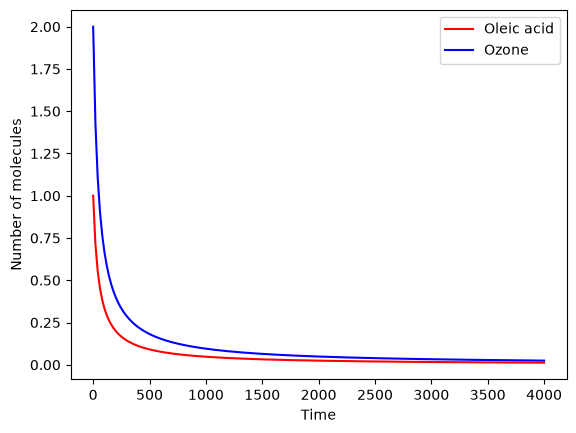

In [29]:
# Setting up kinetics

k1 = 0.01               # rate constant
k2 = 0.02
A0 = 1                   # initial concentration of oleic acid
O30 = 2                 # initial concentration of ozone
t_end = 4000             # final time step

def second_order(t, y):
    oleic = y[0]
    ozone = y[1]

    rate1 = k1 * oleic * ozone
    rate2 = k2 * ozone * oleic

    doleic_dt = - rate1
    dozone_dt = - rate2

    return [doleic_dt, dozone_dt]

sol = solve_ivp(second_order,
                (0.0, t_end),
                [A0, O30],
                t_eval = np.linspace(0, t_end, 200),
                rtol=1e-8, atol=1e-10)

t, A, O3 = sol.t, sol.y[0], sol.y[1]

# Plot concentrations over time
plt.plot(t, A, label="Oleic acid", color ='r')
plt.plot(t, O3, label="Ozone", color='b')
plt.xlabel("Time")
plt.ylabel("Number of molecules")
plt.legend()
plt.show()